# 2. Single-view Mammography Classification

This notebook implements the single-view baseline for the VinDr-Mammo dataset.

The prepared train, validation, and test splits from the previous notebook
are reused to ensure consistent evaluation across all experiments.

The objective is to train and compare mammography classifiers using one
view at a time before introducing multi-view CC+MLO fusion.

## 2.1 Data Preparation

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from PIL import Image

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

### 1. Define paths

In [ ]:
PROJECT_DIR = (
    Path.cwd().parent 
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_DIR / "data"
SPLIT_DIR = DATA_DIR / "splits"

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(SPLIT_DIR / "train_pairs.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_pairs.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_pairs.csv")

In [68]:
print(train_df[["CC_path", "MLO_path", "target"]].head())

                                             CC_path  \
0  D:\images_png\27da2a953a5b5d4f4b87b65dbc2ebe91...   
1  D:\images_png\b927d189be4fcf2cadfbb6d30fbd6bca...   
2  D:\images_png\bdc1f8421da54f78324143bc594507a3...   
3  D:\images_png\357014e8a48f0f7051717aa965f4deb5...   
4  D:\images_png\53e742eb8e91caa870b5dc1fafeec048...   

                                            MLO_path  target  
0  D:\images_png\27da2a953a5b5d4f4b87b65dbc2ebe91...       1  
1  D:\images_png\b927d189be4fcf2cadfbb6d30fbd6bca...       0  
2  D:\images_png\bdc1f8421da54f78324143bc594507a3...       0  
3  D:\images_png\357014e8a48f0f7051717aa965f4deb5...       0  
4  D:\images_png\53e742eb8e91caa870b5dc1fafeec048...       0  


### 2. Load train/val/test pairs

In [61]:
print("Train pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Test pairs:", len(test_df))

Train pairs: 1352
Validation pairs: 1150
Test pairs: 1907


In [8]:
train_df.head()

,study_id,laterality,target,split,CC,MLO,CC_path,MLO_path
0,27da2a953a5b5d4f4b87b65dbc2ebe91,R,1,training,e7ed852e596846ff61f0cea69d9f2ae6,5e16b129e337c2191bd0207390259575,D:\images_png\27da2a953a5b5d4f4b87b65dbc2ebe91...,D:\images_png\27da2a953a5b5d4f4b87b65dbc2ebe91...
1,b927d189be4fcf2cadfbb6d30fbd6bca,R,0,training,e6c7fd736d2b738466a477f1205cd3ad,77f006462a25e16ff8fbf514ca3d4331,D:\images_png\b927d189be4fcf2cadfbb6d30fbd6bca...,D:\images_png\b927d189be4fcf2cadfbb6d30fbd6bca...
2,bdc1f8421da54f78324143bc594507a3,L,0,training,002f7204f82358ad735cd13fea03343a,028cd95e334ed277aadc7c50c024d962,D:\images_png\bdc1f8421da54f78324143bc594507a3...,D:\images_png\bdc1f8421da54f78324143bc594507a3...
3,357014e8a48f0f7051717aa965f4deb5,R,0,training,4993cd4bf4f7802b401d9a9354c43d93,68445f2c248c9be67a8c3460ba0c7257,D:\images_png\357014e8a48f0f7051717aa965f4deb5...,D:\images_png\357014e8a48f0f7051717aa965f4deb5...
4,53e742eb8e91caa870b5dc1fafeec048,L,0,training,36f9a4ed4aa9577f75902081bc6e2319,97369d2a405adf5c50851138e66aa9a2,D:\images_png\53e742eb8e91caa870b5dc1fafeec048...,D:\images_png\53e742eb8e91caa870b5dc1fafeec048...


In [9]:
print(train_df.columns.tolist())

['study_id', 'laterality', 'target', 'split', 'CC', 'MLO', 'CC_path', 'MLO_path']


### 3. Show original class imbalance

In [10]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print(df["target"].value_counts())


Train
target
0    1014
1     338
Name: count, dtype: int64

Validation
target
0    1093
1      57
Name: count, dtype: int64

Test
target
0    1808
1      99
Name: count, dtype: int64


### 4. Leakage

In [12]:
train_ids = set(train_df["study_id"])
val_ids = set(val_df["study_id"])
test_ids = set(test_df["study_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No study-level leakage detected.")

No study-level leakage detected.


The prepared CC/MLO pairs are loaded from the previous notebook. The training set uses a 3:1 negative-to-positive ratio, while validation and test preserve their original class distributions. Study-level separation is verified to prevent data leakage.

## 2.2 PNG Inspection and Preprocessing

Image mode: L
Image size: (912, 1520)
Shape: (1520, 912)
Dtype: uint8
Min intensity: 0
Max intensity: 243


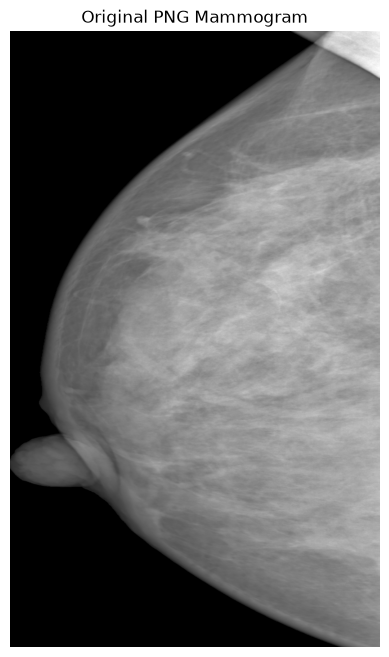

In [37]:
sample_path = Path(train_df.iloc[0]["CC_path"])

with Image.open(sample_path) as img:
    print("Image mode:", img.mode)
    print("Image size:", img.size)

    image = np.array(img.copy())

print("Shape:", image.shape)
print("Dtype:", image.dtype)
print("Min intensity:", image.min())
print("Max intensity:", image.max())

plt.figure(figsize=(6, 8))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.title("Original PNG Mammogram")
plt.show()

PNG mammograms are inspected for image dimensions and intensity characteristics. The preprocessed images are used directly without additional DICOM-specific corrections.

## 2.3 Image Transformation and Dataset

In [38]:
from torchvision.transforms import functional as TF

class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.BILINEAR
        )

        width, height = image.size

        padding = (
            (self.size - width) // 2,
            (self.size - height) // 2,
            self.size - width - (self.size - width) // 2,
            self.size - height - (self.size - height) // 2
        )

        return TF.pad(image, padding, fill=0)

In [39]:
IMAGE_SIZE = 224

image_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),

    transforms.Grayscale(num_output_channels=3),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Images are resized with aspect-ratio preservation, converted to three channels, and normalized using ImageNet statistics for compatibility with pretrained CNNs.

In [43]:
class MammographyDataset(Dataset):

    def __init__(self, dataframe, view="CC", transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.view = view
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = row[f"{self.view}_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            row["target"],
            dtype=torch.float32
        )

        return image, label

In [44]:
train_dataset = MammographyDataset(
    train_df,
    view="CC",
    transform=image_transform
)

val_dataset = MammographyDataset(
    val_df,
    view="CC",
    transform=image_transform
)

test_dataset = MammographyDataset(
    test_df,
    view="CC",
    transform=image_transform
)

In [45]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([3, 224, 224])
Label: tensor(1.)


The dataset class loads a selected mammographic view using the prepared PNG paths and returns a preprocessed image tensor with its breast-level binary label.

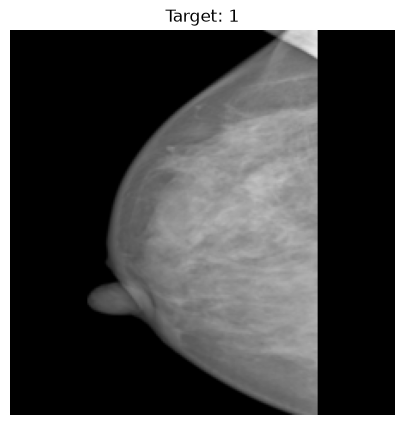

In [62]:
image, label = train_dataset[0]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = (image.cpu() * std + mean).clamp(0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(display_image.permute(1, 2, 0))
plt.title(f"Target: {int(label.item())}")
plt.axis("off")
plt.show()

## 2.4 DataLoader and Device Setup

DataLoaders provide batched image tensors, with shuffling enabled only for training. CUDA acceleration is used when available.

In [47]:
BATCH_SIZE = 8
EPOCHS = 10
LEARNING_RATE = 1e-4

In [48]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 169
Validation batches: 144
Test batches: 239


In [49]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Images shape: torch.Size([8, 3, 224, 224])
Labels shape: torch.Size([8])
Labels: tensor([0., 1., 0., 0., 0., 0., 0., 0.])


In [50]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


## 2.5 Training Utilities

A shared training and evaluation pipeline is used to ensure consistent experimental conditions across architectures.

In [51]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    model.train()

    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)

In [52]:
def evaluate_model(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            probs = torch.sigmoid(logits)

            running_loss += (
                loss.item() * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy().ravel()
            )

            all_probs.extend(
                probs.cpu().numpy().ravel()
            )

    average_loss = (
        running_loss / len(loader.dataset)
    )

    return (
        average_loss,
        np.array(all_labels),
        np.array(all_probs)
    )

In [53]:
def calculate_metrics(
    model,
    loader,
    criterion,
    device
):

    loss, labels, probs = evaluate_model(
        model,
        loader,
        criterion,
        device
    )

    preds = (
        probs >= 0.5
    ).astype(int)

    auroc = roc_auc_score(
        labels,
        probs
    )

    auprc = average_precision_score(
        labels,
        probs
    )

    sensitivity = recall_score(
        labels,
        preds,
        zero_division=0
    )

    precision = precision_score(
        labels,
        preds,
        zero_division=0
    )

    f1 = f1_score(
        labels,
        preds,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        preds,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "loss": loss,
        "auroc": auroc,
        "auprc": auprc,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1": f1
    }

In [54]:
def create_model(model_name, device):

    if model_name == "resnet50":
        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, 1)

    elif model_name == "densenet121":
        model = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )

        in_features = model.classifier.in_features
        model.classifier = nn.Linear(
            in_features,
            1
        )

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        in_features = model.classifier[1].in_features

        model.classifier[1] = nn.Linear(
            in_features,
            1
        )

    else:
        raise ValueError(
            f"Unknown model: {model_name}"
        )

    return model.to(device)

In [55]:
def train_model(
    model_name,
    train_loader,
    val_loader,
    device,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
):

    set_seed()

    model = create_model(
        model_name,
        device
    )

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_epoch = 0
    best_model_state = None

    for epoch in range(epochs):

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_labels, val_probs = evaluate_model(
            model,
            val_loader,
            criterion,
            device
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_model_state = {
                key: value.cpu().clone()
                for key, value
                in model.state_dict().items()
            }

        print(
            f"{model_name} | "
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    model.load_state_dict(
        best_model_state
    )

    model = model.to(device)

    return (
        model,
        train_losses,
        val_losses,
        best_epoch
    )

## 2.6 Architecture Comparison

Three ImageNet-pretrained CNN architectures are compared under the same training configuration and data splits:

- ResNet50
- DenseNet121
- EfficientNet-B0

The same optimizer, learning rate, batch size, number of epochs and evaluation procedure are used for all models.

In [56]:
model_names = [
    "resnet50",
    "densenet121",
    "efficientnet_b0"
]

results = []

trained_models = {}
histories = {}

for model_name in model_names:

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    model, train_losses, val_losses, best_epoch = train_model(
        model_name,
        train_loader,
        val_loader,
        device,
        epochs=EPOCHS,
        learning_rate=LEARNING_RATE
    )

    torch.save(
        {
            "model_name": model_name,
            "state_dict": model.state_dict(),
            "best_epoch": best_epoch,
            "image_size": IMAGE_SIZE,
            "seed": SEED
        },
        MODEL_DIR / f"{model_name}_CC_best.pth"
    )

    criterion = nn.BCEWithLogitsLoss()

    metrics = calculate_metrics(
        model,
        val_loader,
        criterion,
        device
    )

    metrics["model"] = model_name
    metrics["best_epoch"] = best_epoch

    results.append(metrics)

    trained_models[model_name] = model

    histories[model_name] = {
        "train_loss": train_losses,
        "val_loss": val_losses
    }


Training: resnet50
resnet50 | Epoch 01/10 | Train Loss: 0.5470 | Val Loss: 0.3583
resnet50 | Epoch 02/10 | Train Loss: 0.5016 | Val Loss: 0.2730
resnet50 | Epoch 03/10 | Train Loss: 0.4347 | Val Loss: 0.2617
resnet50 | Epoch 04/10 | Train Loss: 0.3351 | Val Loss: 0.5651
resnet50 | Epoch 05/10 | Train Loss: 0.2497 | Val Loss: 0.3263
resnet50 | Epoch 06/10 | Train Loss: 0.1285 | Val Loss: 0.6704
resnet50 | Epoch 07/10 | Train Loss: 0.1129 | Val Loss: 0.3785
resnet50 | Epoch 08/10 | Train Loss: 0.0757 | Val Loss: 0.6008
resnet50 | Epoch 09/10 | Train Loss: 0.1070 | Val Loss: 0.5095
resnet50 | Epoch 10/10 | Train Loss: 0.0399 | Val Loss: 0.3354

Training: densenet121
densenet121 | Epoch 01/10 | Train Loss: 0.5627 | Val Loss: 0.4068
densenet121 | Epoch 02/10 | Train Loss: 0.5237 | Val Loss: 0.5699
densenet121 | Epoch 03/10 | Train Loss: 0.5027 | Val Loss: 0.3299
densenet121 | Epoch 04/10 | Train Loss: 0.4355 | Val Loss: 0.3419
densenet121 | Epoch 05/10 | Train Loss: 0.3806 | Val Loss: 0.41

In [59]:
results_df = pd.DataFrame(
    results
)

results_df = results_df[
    [
        "model",
        "best_epoch",
        "loss",
        "auroc",
        "auprc",
        "sensitivity",
        "specificity",
        "precision",
        "f1"
    ]
]

results_df

,model,best_epoch,loss,auroc,auprc,sensitivity,specificity,precision,f1
0,resnet50,3,0.261664,0.731577,0.226174,0.263158,0.968893,0.306122,0.283019
1,densenet121,8,0.302770,0.675912,0.173720,0.333333,0.923147,0.184466,0.237500
2,efficientnet_b0,2,0.255035,0.701851,0.120362,0.122807,0.969808,0.175000,0.144330


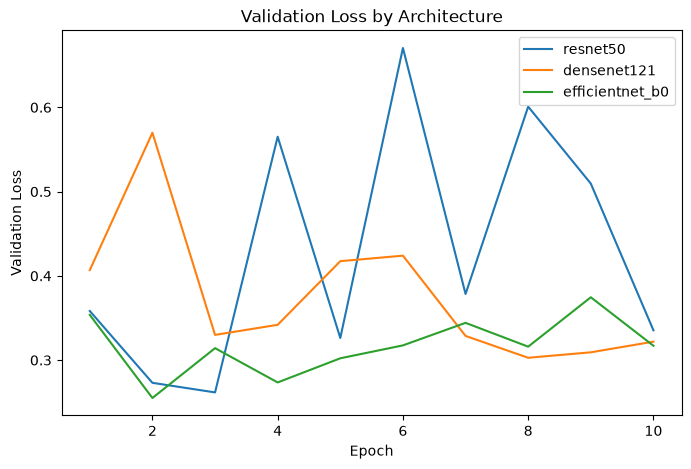

In [60]:
plt.figure(figsize=(8, 5))

for model_name in model_names:
    losses = histories[model_name]["val_loss"]

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss by Architecture")
plt.legend()
plt.show()

ResNet50 achieved the highest validation AUROC, AUPRC, and F1-score among the evaluated architectures. Although DenseNet121 showed higher sensitivity at the default threshold, ResNet50 was selected as the reference model for subsequent experiments.

## 2.7 CC vs MLO Comparison

ResNet50 is evaluated separately on CC and MLO mammographic views using identical training settings and data partitions. This experiment establishes single-view reference results for subsequent multi-view fusion.

In [63]:
mlo_train_dataset = MammographyDataset(
    train_df,
    view="MLO",
    transform=image_transform
)

mlo_val_dataset = MammographyDataset(
    val_df,
    view="MLO",
    transform=image_transform
)

mlo_train_loader = DataLoader(
    mlo_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

mlo_val_loader = DataLoader(
    mlo_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [64]:
mlo_model, mlo_train_losses, mlo_val_losses, mlo_best_epoch = train_model(
    "resnet50",
    mlo_train_loader,
    mlo_val_loader,
    device,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
)

mlo_metrics = calculate_metrics(
    mlo_model,
    mlo_val_loader,
    nn.BCEWithLogitsLoss(),
    device
)

print(pd.Series(mlo_metrics))

resnet50 | Epoch 01/10 | Train Loss: 0.5536 | Val Loss: 0.3776
resnet50 | Epoch 02/10 | Train Loss: 0.4991 | Val Loss: 0.3034
resnet50 | Epoch 03/10 | Train Loss: 0.4148 | Val Loss: 0.3713
resnet50 | Epoch 04/10 | Train Loss: 0.3285 | Val Loss: 0.5512
resnet50 | Epoch 05/10 | Train Loss: 0.2084 | Val Loss: 0.4751
resnet50 | Epoch 06/10 | Train Loss: 0.1425 | Val Loss: 0.3921
resnet50 | Epoch 07/10 | Train Loss: 0.1155 | Val Loss: 0.3731
resnet50 | Epoch 08/10 | Train Loss: 0.0542 | Val Loss: 0.3412
resnet50 | Epoch 09/10 | Train Loss: 0.0744 | Val Loss: 0.6123
resnet50 | Epoch 10/10 | Train Loss: 0.0945 | Val Loss: 0.3492
loss           0.303395
auroc          0.672525
auprc          0.134381
sensitivity    0.157895
specificity    0.959744
precision      0.169811
f1             0.163636
dtype: float64


## 2.8 Single-view Results

In [65]:
cc_metrics = results_df[
    results_df["model"] == "resnet50"
].iloc[0]

comparison_df = pd.DataFrame([
    {
        "View": "CC",
        "AUROC": cc_metrics["auroc"],
        "AUPRC": cc_metrics["auprc"],
        "Sensitivity": cc_metrics["sensitivity"],
        "Specificity": cc_metrics["specificity"],
        "F1": cc_metrics["f1"]
    },
    {
        "View": "MLO",
        "AUROC": mlo_metrics["auroc"],
        "AUPRC": mlo_metrics["auprc"],
        "Sensitivity": mlo_metrics["sensitivity"],
        "Specificity": mlo_metrics["specificity"],
        "F1": mlo_metrics["f1"]
    }
])

comparison_df.round(4)

,View,AUROC,AUPRC,Sensitivity,Specificity,F1
0,CC,0.7316,0.2262,0.2632,0.9689,0.2830
1,MLO,0.6725,0.1344,0.1579,0.9597,0.1636


CC achieved higher validation AUROC, AUPRC, and F1-score than MLO under the same training configuration. However, both models showed low sensitivity at the default decision threshold, indicating that many suspicious cases were missed.

In [ ]:
torch.save(
    {
        "model_name": "resnet50",
        "view": "MLO",
        "state_dict": mlo_model.state_dict(),
        "best_epoch": mlo_best_epoch,
        "image_size": IMAGE_SIZE,
        "seed": SEED
    },
    MODEL_DIR / "resnet50_MLO_best.pth"
)

results_df.to_csv(
    PROJECT_DIR / "results" / "experiments" / "architecture_results.csv",
    index=False
)

comparison_df.to_csv(
    PROJECT_DIR / "results" / "experiments" / "single_view_comparison.csv",
    index=False
)